# Check gridded decomp (mapping LAI/aridity bins back to lat/lon cells)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

import etunc.config as cfg
import etunc.plotting as plotting

In [2]:
RUN_IDS = ["r5b27e56", "r59533f4", "r1166e5e"]
BIN_VARIABLE = "et"
EDGES = "pooled_all"

def stem() -> str:
    return f"all.{BIN_VARIABLE}_clim.decomp_gridded.qbin_{EDGES}"

In [3]:
decomp = {}
for run_id in RUN_IDS:
    _settings = cfg.run_settings(run_id)
    assert _settings["binning"]["n_xbins"] == _settings["binning"]["n_ybins"]
    nbins = str(_settings["binning"]["n_xbins"])
    print(f"{run_id}: BINS={nbins}")
    decomp[nbins] = {}
    for f in cfg.FAMILIES:
        out_dir = cfg.output_dir(cfg.PROC_ROOT, "all", "decomp", run_id)
        p = out_dir / f"{stem()}.{f}.{run_id}.nc"
        decomp[nbins][f] = xr.open_dataset(p)
        decomp[nbins][f]["BINNED"] = decomp[nbins][f]["STATE"] + decomp[nbins][f]["FUNCTION"] + decomp[nbins][f]["INTERACTION"]

r5b27e56: BINS=10
r59533f4: BINS=15
r1166e5e: BINS=20


In [6]:
decomp["15"]["cmip"].obs_reference

<xarray.DataArray 'obs_reference' (obs_reference: 13)> Size: 2kB
array(['CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'DOLCE-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'FLUXCOM-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'GLEAMv3.3a-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'MOD16A2-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'MODIS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'WECANN-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'PMLv2.2a_MODIS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'PMLv2.2c-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'GLEAMv4.3a-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'GLEAMv4.3b-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
       'SiTHv2-GIMMS_LAI4g-GPCPv2.3-CERESed4.2', 'obs_pooled'], dtype='<U46')
Coordinates:
  * obs_reference    (obs_reference) <U46 2kB 'CLASS-GIMMS_LAI4g-GPCPv2.3-CER...
    ref_et_product   (obs_reference) <U14 728B ...
    ref_lai_product  (obs_reference) <U11 572B ...
    ref_pr_product   (obs_reference) <U8 416B ...
    ref_rn_product   (obs_reference) <U10 520B ...
    ltype            int64 8B ...
    landunit         <U40 160B ...

In [4]:
decomp["15"]["cmip"].dataset.values

array(['cmip.ACCESS-ESM1-5.r1i1p1f1', 'cmip.AWI-ESM-1-1-LR.r1i1p1f1',
       'cmip.BCC-ESM1.r1i1p1f1', 'cmip.CESM2.r1i1p1f1',
       'cmip.CESM2-FV2.r1i1p1f1', 'cmip.CESM2-WACCM.r1i1p1f1',
       'cmip.CESM2-WACCM-FV2.r1i1p1f1', 'cmip.CMCC-CM2-SR5.r1i1p1f1',
       'cmip.CMCC-ESM2.r1i1p1f1', 'cmip.CNRM-CM6-1.r1i1p1f2',
       'cmip.CNRM-CM6-1-HR.r1i1p1f2', 'cmip.CNRM-ESM2-1.r1i1p1f2',
       'cmip.CanESM5.r1i1p1f1', 'cmip.CanESM5-1.r1i1p1f1',
       'cmip.CanESM5-CanOE.r1i1p2f1', 'cmip.E3SM-1-0.r1i1p1f1',
       'cmip.E3SM-1-1.r1i1p1f1', 'cmip.E3SM-1-1-ECA.r1i1p1f1',
       'cmip.E3SM-2-0.r1i1p1f1', 'cmip.E3SM-2-0-NARRM.r1i1p1f1',
       'cmip.E3SM-2-1.r1i1p1f1', 'cmip.EC-Earth3-Veg.r1i1p1f1',
       'cmip.EC-Earth3-Veg-LR.r1i1p1f1', 'cmip.FGOALS-g3.r1i1p1f1',
       'cmip.GFDL-ESM4.r1i1p1f1', 'cmip.GISS-E2-1-G.r1i1p1f1',
       'cmip.GISS-E2-1-G-CC.r1i1p1f1', 'cmip.GISS-E2-1-H.r1i1p1f1',
       'cmip.GISS-E2-2-G.r1i1p1f1', 'cmip.GISS-E3-G.r1i1p101f1',
       'cmip.HadGEM3-GC31-LL.r1i1

Text(0.5, 1.0, 'WITHIN')

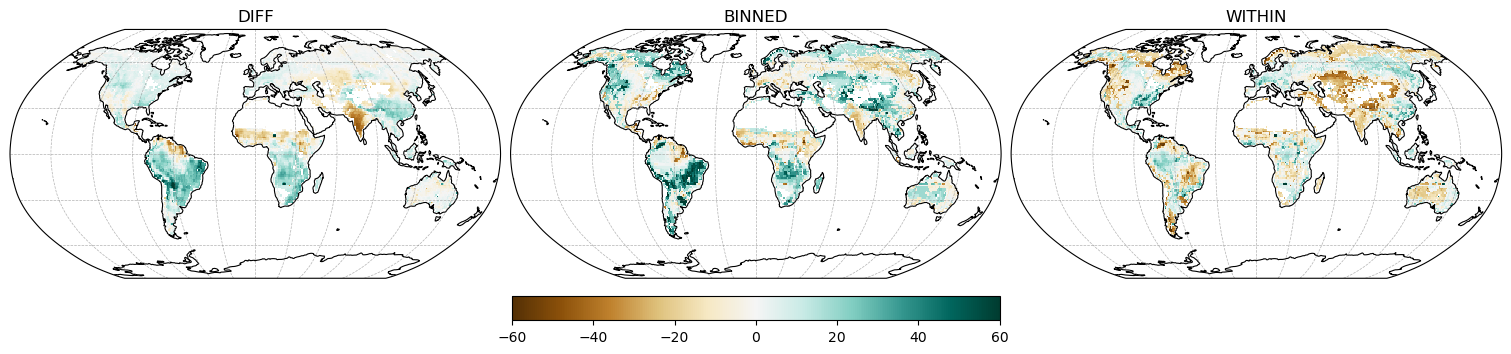

In [10]:
obs_ref = "GLEAMv4.3a-GIMMS_LAI4g-GPCPv2.3-CERESed4.2"
cmip_dataset = "cmip.UKESM1-0-LL.r1i1p1f2"
nbins = "15"

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained", subplot_kw={"projection": ccrs.Robinson()})
axs = axes.ravel()

decomp[nbins]["cmip"]["DIFF"].sel(dataset=cmip_dataset, obs_reference=obs_ref).plot(
    ax=axs[0],
    add_labels=False, add_colorbar=False,
    vmin=-60, vmax=60, cmap="BrBG",
    transform=ccrs.PlateCarree(),
)
decomp[nbins]["cmip"]["BINNED"].sel(dataset=cmip_dataset, obs_reference=obs_ref).plot(
    ax=axs[1],
    add_labels=False, add_colorbar=False,
    vmin=-60, vmax=60, cmap="BrBG",
    transform=ccrs.PlateCarree(),
)
mp = decomp[nbins]["cmip"]["WITHIN"].sel(dataset=cmip_dataset, obs_reference=obs_ref).plot(
    ax=axs[2],
    add_labels=False, add_colorbar=False,
    vmin=-60, vmax=60, cmap="BrBG",
    transform=ccrs.PlateCarree(),
)

cb = fig.colorbar(
    mp,
    ax=axs,
    location="bottom",
    fraction=0.075
)

for ax in axs:
    plotting.map_ax(ax, slice(-90, 90))
    ax.set_global()

axs[0].set_title("DIFF")
axs[1].set_title("BINNED")
axs[2].set_title("WITHIN")

## How much of each gridcell's DIFF do the bins explain?

At every gridcell DIFF = e_m − e_r = BINNED + WITHIN, with BINNED = STATE + FUNCTION + INTERACTION = f_m(b_m) − f_r(b_r) (the difference of the bin means) and WITHIN the difference of the within-bin anomalies. Land-area weighted over the gridcells on the common support (cells with any bin off the support dropped):

Var(DIFF) = Var(BINNED) + Var(WITHIN) + 2 Cov(BINNED, WITHIN)

- `frac_BINNED`, `frac_WITHIN`, `frac_2COV`: each term / Var(DIFF) (they sum to 1)
- `r2_BINNED`: corr(BINNED, DIFF)², the fraction of the spatial variance of DIFF a linear fit on BINNED explains
- `std_DIFF`: spatial std of DIFF (W m-2); `land_on_support`: fraction of the valid land kept; `max_identity_err`: max |DIFF − BINNED − WITHIN| (W m-2, should be ~0)

Every dataset against `REF`; the table shows the pooled dataset and the median of the members of each family.

In [13]:
import etunc.grid as rg

REF = "obs_pooled"
NBINS = "15"  # the run of the gridcell partition below (a key of decomp)
TARGET_RES = cfg.run_settings(RUN_IDS[0])["prep"]["target_res"]
assert all(cfg.run_settings(r)["prep"]["target_res"] == TARGET_RES for r in RUN_IDS)
land_area = rg.land_area(rg.target_grid(TARGET_RES))  # the weights of bin_all_clim.py


def binned_vs_within(ds: xr.Dataset) -> xr.Dataset:
    """
    Land-area weighted partition of the variance of DIFF over the gridcells on the common support,
    with BINNED = STATE + FUNCTION + INTERACTION (= E_mm - E_rr) and DIFF = BINNED + WITHIN:
    Var(DIFF) = Var(BINNED) + Var(WITHIN) + 2 Cov(BINNED, WITHIN), each as a fraction of Var(DIFF).
    Gridcells with any bin off the common support (OFF_SUPPORT_m or _r > 0) are dropped.
    """
    binned = ds["STATE"] + ds["FUNCTION"] + ds["INTERACTION"]
    within, diff = ds["WITHIN"], ds["DIFF"]
    valid = diff.notnull()
    on_support = valid & (ds["OFF_SUPPORT_m"] == 0) & (ds["OFF_SUPPORT_r"] == 0)
    a_all = land_area.sel(lat=ds.lat, lon=ds.lon)
    a = a_all.where(on_support)

    def wmean(x):
        return (a * x).sum(("lat", "lon")) / a.sum(("lat", "lon"))

    def wcov(x, y):
        return wmean((x - wmean(x)) * (y - wmean(y)))

    var_diff = wcov(diff, diff)
    return xr.Dataset({
        "var_BINNED": wcov(binned, binned),
        "var_WITHIN": wcov(within, within),
        "2COV": 2 * wcov(binned, within),
        "frac_BINNED": wcov(binned, binned) / var_diff,
        "frac_WITHIN": wcov(within, within) / var_diff,
        "frac_2COV": 2 * wcov(binned, within) / var_diff,
        "r2_BINNED": wcov(binned, diff) ** 2 / (wcov(binned, binned) * var_diff),  # corr(BINNED, DIFF)^2
        "std_DIFF": np.sqrt(var_diff),  # W m-2
        "land_on_support": a.sum(("lat", "lon")) / a_all.where(valid).sum(("lat", "lon")),
        "max_identity_err": abs(diff - binned - within).max(("lat", "lon")),  # W m-2, should be ~0
    })


# Every dataset of each family against REF (obs: each obs source against obs_pooled)
parts = {f: binned_vs_within(ds.sel(obs_reference=REF)).load() for f, ds in decomp[NBINS].items()}

In [15]:
# Summary: the pooled dataset (if any) and the median over the members of each family
rows = []
for f, p in parts.items():
    df = p.drop_vars([c for c in p.coords if c != "dataset"]).to_dataframe()
    pooled = df.index.str.endswith("_pooled")
    if pooled.any():
        rows.append(df[pooled].assign(family=f, n=1))
    members = df[~pooled]
    rows.append(members.median().to_frame(f"{f} members (median)").T.assign(family=f, n=len(members)))
summary = pd.concat(rows)
with pd.option_context("display.width", 250, "display.max_columns", 20, "display.float_format", "{:.3f}".format):
    print(summary)

                            var_BINNED  var_WITHIN     2COV  frac_BINNED  frac_WITHIN  frac_2COV  r2_BINNED  std_DIFF  land_on_support  max_identity_err     family   n
obs members (median)            19.320      23.678   -1.591        0.469        0.648     -0.037      0.353     6.329            0.999             0.000        obs  12
era5_pooled                     41.750      58.857  -33.735        0.624        0.880     -0.504      0.222     8.178            0.998             0.000       era5   1
era5 members (median)           41.750      58.857  -33.735        0.624        0.880     -0.504      0.222     8.178            0.998             0.000       era5   1
cmip_pooled                    120.861      98.016 -167.927        2.372        1.924     -3.296      0.221     7.138            0.815             0.000       cmip   1
cmip members (median)          287.383     175.561 -291.318        1.445        1.149     -1.533      0.411    12.577            0.976             0.000       c

## Variance partition vs aggregation scale

The same partition, Var(DIFF) = Var(BINNED) + Var(WITHIN) + 2 Cov(BINNED, WITHIN), across land-area weighted means of the maps over larger areas instead of gridcells:

- **blocks** of k × k gridcells (block side `block_deg` = k × `TARGET_RES`; 1 deg = the gridcell partition above), each block weighted by its land area on the common support;
- **AR6 land regions** (gridcell centers; cells outside every AR6 land region are dropped).

The block means are linear, so DIFF = BINNED + WITHIN holds for every block. By the law of total variance, the variance across blocks of size L is the part of the gridcell variance that comes from scales larger than L. The curve against L works like a variogram: it shows at which scales Var(BINNED), Var(WITHIN) and their covariance live. If the cancellation of BINNED and WITHIN is small-scale noise (e.g. gridcells jumping between neighbouring bins), 2 Cov should shrink faster than Var(DIFF) as L grows.

Caveats: blocks are in degrees, not equal-area (high-latitude blocks hold less land and weigh less), and the largest blocks leave only a few dozen blocks, so the right end of the curves is noisy.

Runtime: about 7 minutes for the three bin counts.

In [12]:
import regionmask

BLOCK_CELLS = [1, 2, 3, 5, 10, 15, 20, 30]  # block side in gridcells; x TARGET_RES = block side in degrees


def on_support_terms(ds: xr.Dataset) -> tuple[xr.Dataset, xr.DataArray]:
    """DIFF, BINNED and WITHIN on the common support (NaN off it), and the land-area weights (0 off it)."""
    on = ds["DIFF"].notnull() & (ds["OFF_SUPPORT_m"] == 0) & (ds["OFF_SUPPORT_r"] == 0)
    x = xr.Dataset({"DIFF": ds["DIFF"], "BINNED": ds["STATE"] + ds["FUNCTION"] + ds["INTERACTION"],
                    "WITHIN": ds["WITHIN"]}).where(on)
    a = land_area.sel(lat=ds.lat, lon=ds.lon).where(on, 0.0)
    return x, a


def partition(x: xr.Dataset, a: xr.DataArray, dims) -> xr.Dataset:
    """Var(DIFF) = Var(BINNED) + Var(WITHIN) + 2 Cov(BINNED, WITHIN) across `dims`, weighted by `a`."""
    def wmean(v):
        return (a * v).sum(dims) / a.sum(dims)

    def wcov(u, v):
        return wmean((u - wmean(u)) * (v - wmean(v)))

    var_diff = wcov(x["DIFF"], x["DIFF"])
    out = xr.Dataset({
        "var_DIFF": var_diff,
        "var_BINNED": wcov(x["BINNED"], x["BINNED"]),
        "var_WITHIN": wcov(x["WITHIN"], x["WITHIN"]),
        "2cov": 2 * wcov(x["BINNED"], x["WITHIN"]),
    })
    for v in ("var_BINNED", "var_WITHIN", "2cov"):
        out[f"frac_{v.removeprefix('var_')}"] = out[v] / var_diff  # frac_BINNED + frac_WITHIN + frac_2cov = 1
    out["r2_BINNED"] = wcov(x["BINNED"], x["DIFF"]) ** 2 / (out["var_BINNED"] * var_diff)
    return out


def block_means(x: xr.Dataset, a: xr.DataArray, k: int) -> tuple[xr.Dataset, xr.DataArray]:
    """Land-area weighted means over blocks of k x k gridcells, and each block's land area on the support."""
    a_blk = a.coarsen(lat=k, lon=k, boundary="pad").sum()
    x_blk = (x * a).coarsen(lat=k, lon=k, boundary="pad").sum() / a_blk
    return x_blk.where(a_blk > 0), a_blk


def region_means(x: xr.Dataset, a: xr.DataArray, mask: xr.DataArray) -> tuple[xr.Dataset, xr.DataArray]:
    """Land-area weighted means over the regions of `mask` (region, lat, lon), and each region's land area."""
    m = mask.astype(float)
    a_reg = xr.dot(a, m, dim=["lat", "lon"])
    x_reg = (x * a).fillna(0.0).map(lambda v: xr.dot(v, m, dim=["lat", "lon"])) / a_reg
    return x_reg.where(a_reg > 0), a_reg


def family_summary(p: xr.Dataset, stat: str = "median") -> xr.Dataset:
    """Median (or q25, q75) over the members of a family (the datasets not ending in _pooled)."""
    members = p.isel(dataset=~p["dataset"].str.endswith("_pooled"))
    q = {"median": 0.5, "q25": 0.25, "q75": 0.75}[stat]
    return members.quantile(q, dim="dataset").drop_vars("quantile")


# AR6 land regions (by gridcell center), on the grid of the maps
_grid = decomp[NBINS]["obs"]
ar6 = regionmask.defined_regions.ar6.land.mask_3D(_grid.lon, _grid.lat)

# For every bin count and family, every dataset vs REF: the partition across blocks of each size
# (along block_deg, the block side in degrees) and across the AR6 regions
scale_parts, ar6_parts = {}, {}
for nbins, fams in decomp.items():
    scale_parts[nbins], ar6_parts[nbins] = {}, {}
    for f, ds in fams.items():
        x, a = on_support_terms(ds.sel(obs_reference=REF).load())
        per_k = [partition(*block_means(x, a, k), ("lat", "lon")) for k in BLOCK_CELLS]
        scale_parts[nbins][f] = xr.concat(per_k, dim="block_deg").assign_coords(
            block_deg=[k * TARGET_RES for k in BLOCK_CELLS])
        ar6_parts[nbins][f] = partition(*region_means(x, a, ar6), "region")
    print(f"{nbins} bins done")

10 bins done
15 bins done
20 bins done


In [13]:
# Table: median over the members of each family, NBINS bins, at a few block sizes and the AR6 regions
COLS = ["frac_BINNED", "frac_WITHIN", "frac_2cov", "r2_BINNED", "var_DIFF"]
rows = []
for f in decomp[NBINS]:
    med = family_summary(scale_parts[NBINS][f])
    for L in (1, 5, 10, 30):
        rows.append({"family": f, "scale": f"{L} deg", **{c: float(med[c].sel(block_deg=L)) for c in COLS}})
    med = family_summary(ar6_parts[NBINS][f])
    rows.append({"family": f, "scale": "AR6 regions", **{c: float(med[c]) for c in COLS}})
with pd.option_context("display.width", 250, "display.max_rows", 100, "display.float_format", "{:.3f}".format):
    print(pd.DataFrame(rows).set_index(["family", "scale"]))

                       frac_BINNED  frac_WITHIN  frac_2cov  r2_BINNED  var_DIFF
family    scale                                                                
obs       1 deg              0.469        0.648     -0.037      0.353    40.051
          5 deg              0.408        0.504      0.100      0.506    29.083
          10 deg             0.425        0.453      0.149      0.566    24.871
          30 deg             0.437        0.338      0.199      0.685    16.226
          AR6 regions        0.420        0.411      0.186      0.621    19.530
era5      1 deg              0.624        0.880     -0.504      0.222    66.872
          5 deg              0.537        0.647     -0.184      0.369    41.915
          10 deg             0.521        0.615     -0.136      0.394    30.165
          30 deg             0.528        0.581     -0.109      0.424    15.631
          AR6 regions        0.541        0.522     -0.063      0.480    20.972
cmip      1 deg              1.445      

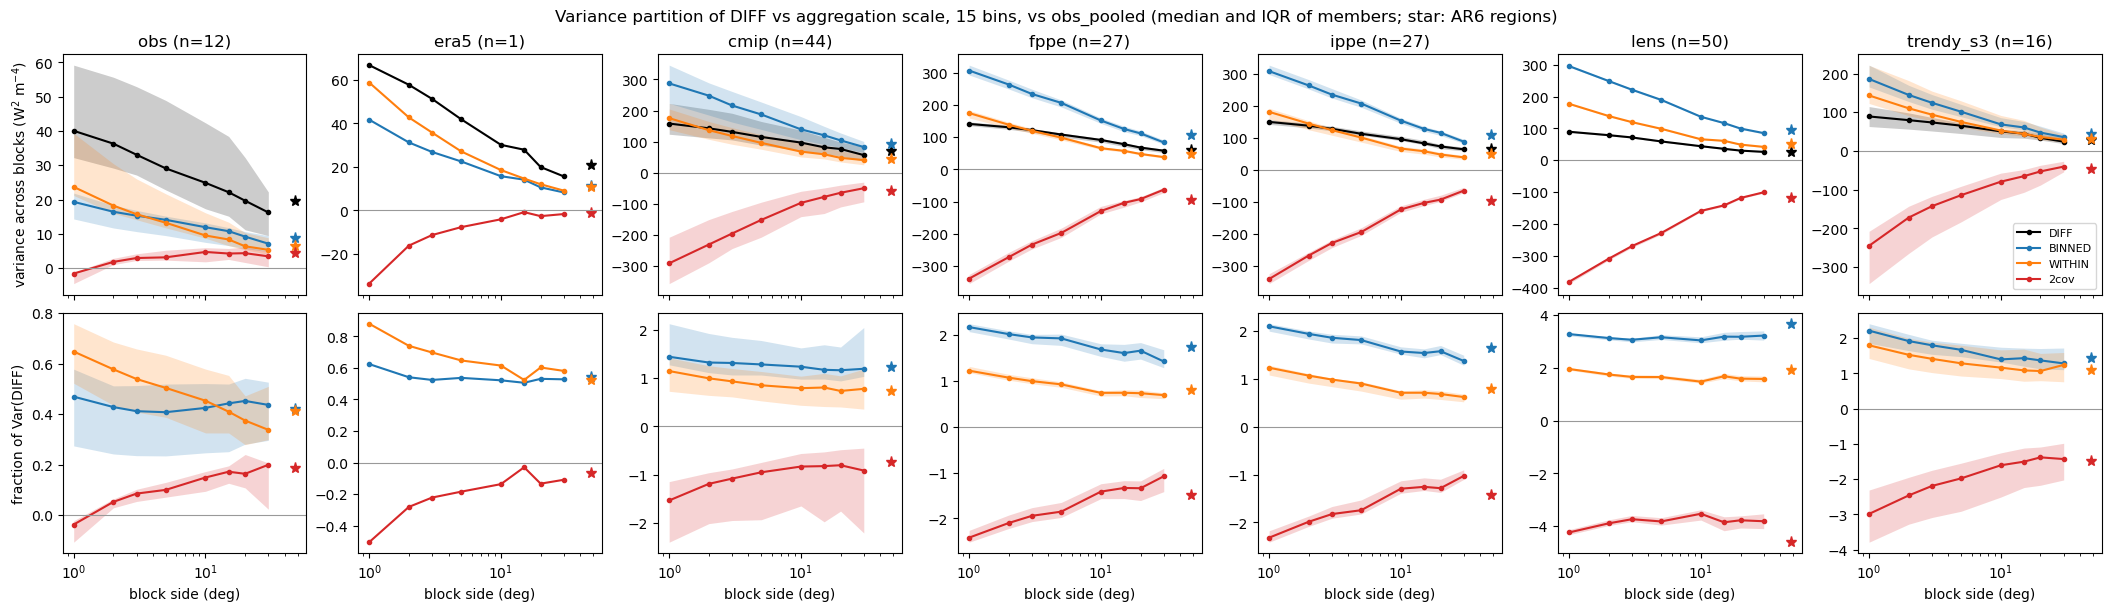

In [14]:
# "Variogram": variance across blocks (top) and fraction of Var(DIFF) (bottom) vs block side, NBINS bins.
# Lines: median of the members; bands: their interquartile range; stars (right of the curves): AR6 regions
TERM_STYLES = {"DIFF": "k", "BINNED": "C0", "WITHIN": "C1", "2cov": "C3"}
families = list(decomp[NBINS])
fig, axes = plt.subplots(2, len(families), figsize=(3 * len(families), 6), sharex=True, layout="constrained")
for j, f in enumerate(families):
    p = scale_parts[NBINS][f]
    med, lo, hi = (family_summary(p, s) for s in ("median", "q25", "q75"))
    reg = family_summary(ar6_parts[NBINS][f])
    L = med["block_deg"]
    for row, prefix in ((0, "var_"), (1, "frac_")):
        ax = axes[row, j]
        for term, c in TERM_STYLES.items():
            if row == 1 and term == "DIFF":
                continue  # frac_DIFF = 1
            name = term if term == "2cov" and row == 0 else prefix + term
            ax.plot(L, med[name], color=c, marker="o", ms=3, label=term)
            ax.fill_between(L, lo[name], hi[name], color=c, alpha=0.2, lw=0)
            ax.plot(L.max() * 1.6, float(reg[name]), marker="*", color=c, ms=8, ls="none")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_xscale("log")
    n_members = int((~p["dataset"].str.endswith("_pooled")).sum())
    axes[0, j].set_title(f"{f} (n={n_members})")
axes[0, 0].set_ylabel("variance across blocks (W$^2$ m$^{-4}$)")
axes[1, 0].set_ylabel("fraction of Var(DIFF)")
for ax in axes[1]:
    ax.set_xlabel("block side (deg)")
axes[0, -1].legend(fontsize=8)
fig.suptitle(f"Variance partition of DIFF vs aggregation scale, {NBINS} bins, vs {REF} "
             "(median and IQR of members; star: AR6 regions)");

## Bin count sensitivity

The same partitions for the runs with 10, 15 and 20 LAI and AI bins (`aw_bins10`, `aw_bins15`, `aw_bins20`; same prep inputs, only the bin counts differ). If the cancellation of BINNED and WITHIN came from the discretisation (gridcells jumping between quantile bins whose means differ), it should change with the bin count: finer bins put each bin mean closer to its gridcells' ET, so WITHIN and the cancellation should shrink and r² should rise.

In [15]:
# Table: median over the members of each family, at the gridcell scale and across the AR6 regions, per bin count
rows = []
for f in decomp[NBINS]:
    for nbins in decomp:
        cell = family_summary(scale_parts[nbins][f]).sel(block_deg=TARGET_RES)
        reg = family_summary(ar6_parts[nbins][f])
        rows.append({"family": f, "bins": nbins,
                     **{f"cell {c}": float(cell[c]) for c in ("var_BINNED", "var_WITHIN", "2cov", "frac_2cov", "r2_BINNED")},
                     **{f"AR6 {c}": float(reg[c]) for c in ("frac_BINNED", "frac_2cov", "r2_BINNED")}})
with pd.option_context("display.width", 250, "display.max_rows", 100, "display.max_columns", 20,
                       "display.float_format", "{:.3f}".format):
    print(pd.DataFrame(rows).set_index(["family", "bins"]))

                cell var_BINNED  cell var_WITHIN  cell 2cov  cell frac_2cov  cell r2_BINNED  AR6 frac_BINNED  AR6 frac_2cov  AR6 r2_BINNED
family    bins                                                                                                                            
obs       10             18.504           24.364     -1.478          -0.031           0.334            0.411          0.172          0.616
          15             19.320           23.678     -1.591          -0.037           0.353            0.420          0.186          0.621
          20             20.567           23.434     -1.975          -0.049           0.376            0.439          0.205          0.666
era5      10             36.928           58.261    -28.003          -0.417           0.212            0.545         -0.087          0.461
          15             41.750           58.857    -33.735          -0.504           0.222            0.541         -0.063          0.480
          20             44

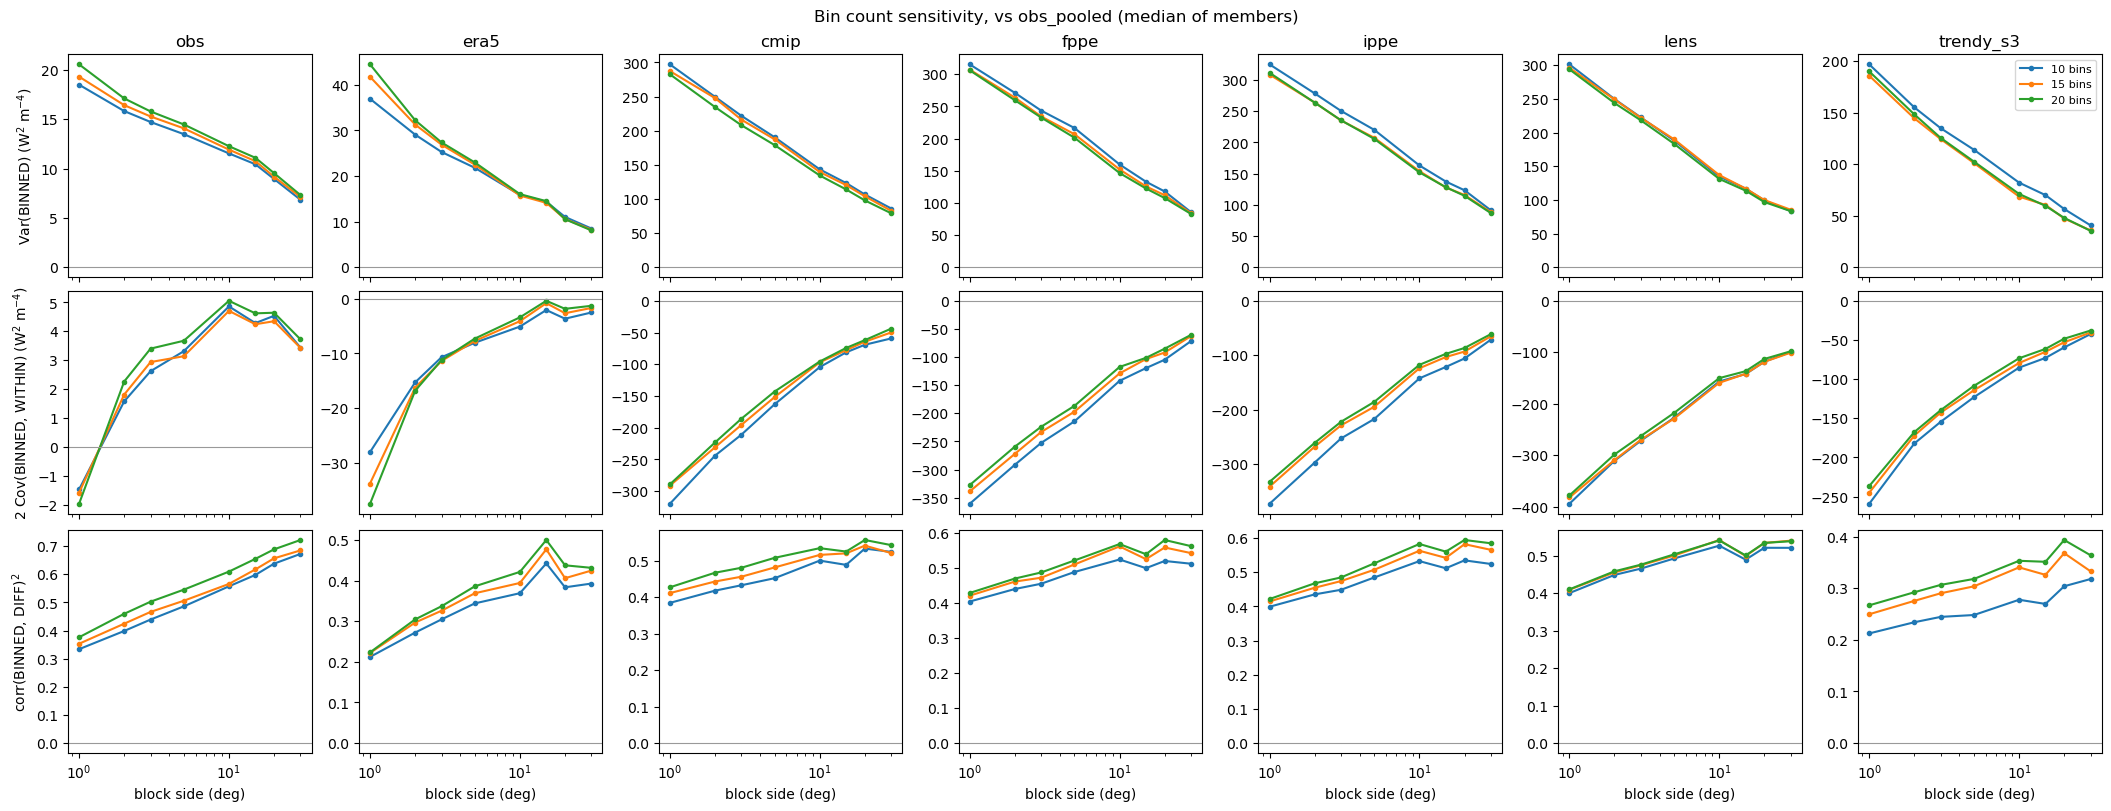

In [16]:
# Var(BINNED), 2 Cov(BINNED, WITHIN) and corr(BINNED, DIFF)^2 vs block side, one line per bin count
# (median of the members)
fig, axes = plt.subplots(3, len(families), figsize=(3 * len(families), 8), sharex=True, layout="constrained")
for j, f in enumerate(families):
    for nbins, c in zip(decomp, ("C0", "C1", "C2")):
        med = family_summary(scale_parts[nbins][f])
        for i, v in enumerate(("var_BINNED", "2cov", "r2_BINNED")):
            axes[i, j].plot(med["block_deg"], med[v], color=c, marker="o", ms=3, label=f"{nbins} bins")
    axes[0, j].set_title(f)
    for ax in axes[:, j]:
        ax.set_xscale("log")
        ax.axhline(0, color="0.6", lw=0.8)
axes[0, 0].set_ylabel("Var(BINNED) (W$^2$ m$^{-4}$)")
axes[1, 0].set_ylabel("2 Cov(BINNED, WITHIN) (W$^2$ m$^{-4}$)")
axes[2, 0].set_ylabel("corr(BINNED, DIFF)$^2$")
for ax in axes[-1]:
    ax.set_xlabel("block side (deg)")
axes[0, -1].legend(fontsize=8)
fig.suptitle(f"Bin count sensitivity, vs {REF} (median of members)");

## Which term does WITHIN cancel?

BINNED = STATE + FUNCTION + INTERACTION, so the covariance term splits exactly:

2 Cov(BINNED, WITHIN) = 2 Cov(STATE, WITHIN) + 2 Cov(FUNCTION, WITHIN) + 2 Cov(INTERACTION, WITHIN)

Per term T, at each aggregation scale (blocks and AR6 regions, as above; `NBINS` bins, vs `REF`):
- `frac_2cov_<T>` = 2 Cov(T, WITHIN) / Var(DIFF): the three sum to `frac_2cov` of the partition above;
- `corr_<T>` = corr(T, WITHIN), the same without the size of T;
- `frac_var_<T>` = Var(T) / Var(DIFF), for scale.

The medians over the members are taken per column, so the median `frac_2cov_<T>` do not add up exactly to the median `frac_2cov`.

Note: STATE + INTERACTION = f_m(b_m) − f_m(b_r), the state change evaluated with m's own bin means. So a negative Cov(STATE, WITHIN) together with a positive Cov(INTERACTION, WITHIN) partly cancels within that sum.

Runtime: about 3 minutes.

In [17]:
TERMS = ("STATE", "FUNCTION", "INTERACTION")


def on_support_components(ds: xr.Dataset) -> tuple[xr.Dataset, xr.DataArray]:
    """DIFF, STATE, FUNCTION, INTERACTION and WITHIN on the common support (NaN off it), and the land-area weights."""
    on = ds["DIFF"].notnull() & (ds["OFF_SUPPORT_m"] == 0) & (ds["OFF_SUPPORT_r"] == 0)
    x = ds[["DIFF", *TERMS, "WITHIN"]].where(on)
    a = land_area.sel(lat=ds.lat, lon=ds.lon).where(on, 0.0)
    return x, a


def cov_split(x: xr.Dataset, a: xr.DataArray, dims) -> xr.Dataset:
    """
    2 Cov(BINNED, WITHIN) = sum over T in TERMS of 2 Cov(T, WITHIN), across `dims` weighted by `a`:
    frac_2cov_<T> = 2 Cov(T, WITHIN) / Var(DIFF) (they sum to frac_2cov of `partition`),
    corr_<T> = corr(T, WITHIN), and frac_var_<T> = Var(T) / Var(DIFF) for scale.
    """
    def wmean(v):
        return (a * v).sum(dims) / a.sum(dims)

    def wcov(u, v):
        return wmean((u - wmean(u)) * (v - wmean(v)))

    var_diff, var_within = wcov(x["DIFF"], x["DIFF"]), wcov(x["WITHIN"], x["WITHIN"])
    out = xr.Dataset()
    for t in TERMS:
        cov_t, var_t = wcov(x[t], x["WITHIN"]), wcov(x[t], x[t])
        out[f"frac_2cov_{t}"] = 2 * cov_t / var_diff
        out[f"corr_{t}"] = cov_t / np.sqrt(var_t * var_within)
        out[f"frac_var_{t}"] = var_t / var_diff
    out["frac_2cov"] = sum(out[f"frac_2cov_{t}"] for t in TERMS)  # = frac_2cov of `partition`
    return out


# Every dataset vs REF, NBINS bins: across blocks of each size (along block_deg) and across the AR6 regions
cov_parts, cov_ar6 = {}, {}
for f, ds in decomp[NBINS].items():
    x, a = on_support_components(ds.sel(obs_reference=REF).load())
    per_k = [cov_split(*block_means(x, a, k), ("lat", "lon")) for k in BLOCK_CELLS]
    cov_parts[f] = xr.concat(per_k, dim="block_deg").assign_coords(block_deg=[k * TARGET_RES for k in BLOCK_CELLS])
    cov_ar6[f] = cov_split(*region_means(x, a, ar6), "region")
    print(f"{f} done")

obs done
era5 done
cmip done
fppe done
ippe done
lens done
trendy_s3 done


In [18]:
# Table: median over the members of each family, at the gridcell scale, 10 deg blocks and the AR6 regions
COLS = ([f"frac_2cov_{t}" for t in TERMS] + ["frac_2cov"] + [f"corr_{t}" for t in TERMS]
        + [f"frac_var_{t}" for t in TERMS])
rows = []
for f in decomp[NBINS]:
    med = family_summary(cov_parts[f])
    for L in (TARGET_RES, 10):
        rows.append({"family": f, "scale": f"{L:g} deg", **{c: float(med[c].sel(block_deg=L)) for c in COLS}})
    med = family_summary(cov_ar6[f])
    rows.append({"family": f, "scale": "AR6 regions", **{c: float(med[c]) for c in COLS}})
with pd.option_context("display.width", 300, "display.max_rows", 100, "display.max_columns", 20,
                       "display.float_format", "{:.3f}".format):
    print(pd.DataFrame(rows).set_index(["family", "scale"]))

                       frac_2cov_STATE  frac_2cov_FUNCTION  frac_2cov_INTERACTION  frac_2cov  corr_STATE  corr_FUNCTION  corr_INTERACTION  frac_var_STATE  frac_var_FUNCTION  frac_var_INTERACTION
family    scale                                                                                                                                                                                   
obs       1 deg                 -0.020              -0.009                 -0.008     -0.037      -0.141         -0.010            -0.089           0.011              0.426                 0.002
          10 deg                -0.001               0.142                  0.001      0.149      -0.031          0.190             0.056           0.001              0.432                 0.000
          AR6 regions            0.001               0.180                  0.001      0.186       0.007          0.257             0.152           0.000              0.414                 0.000
era5      1 deg          

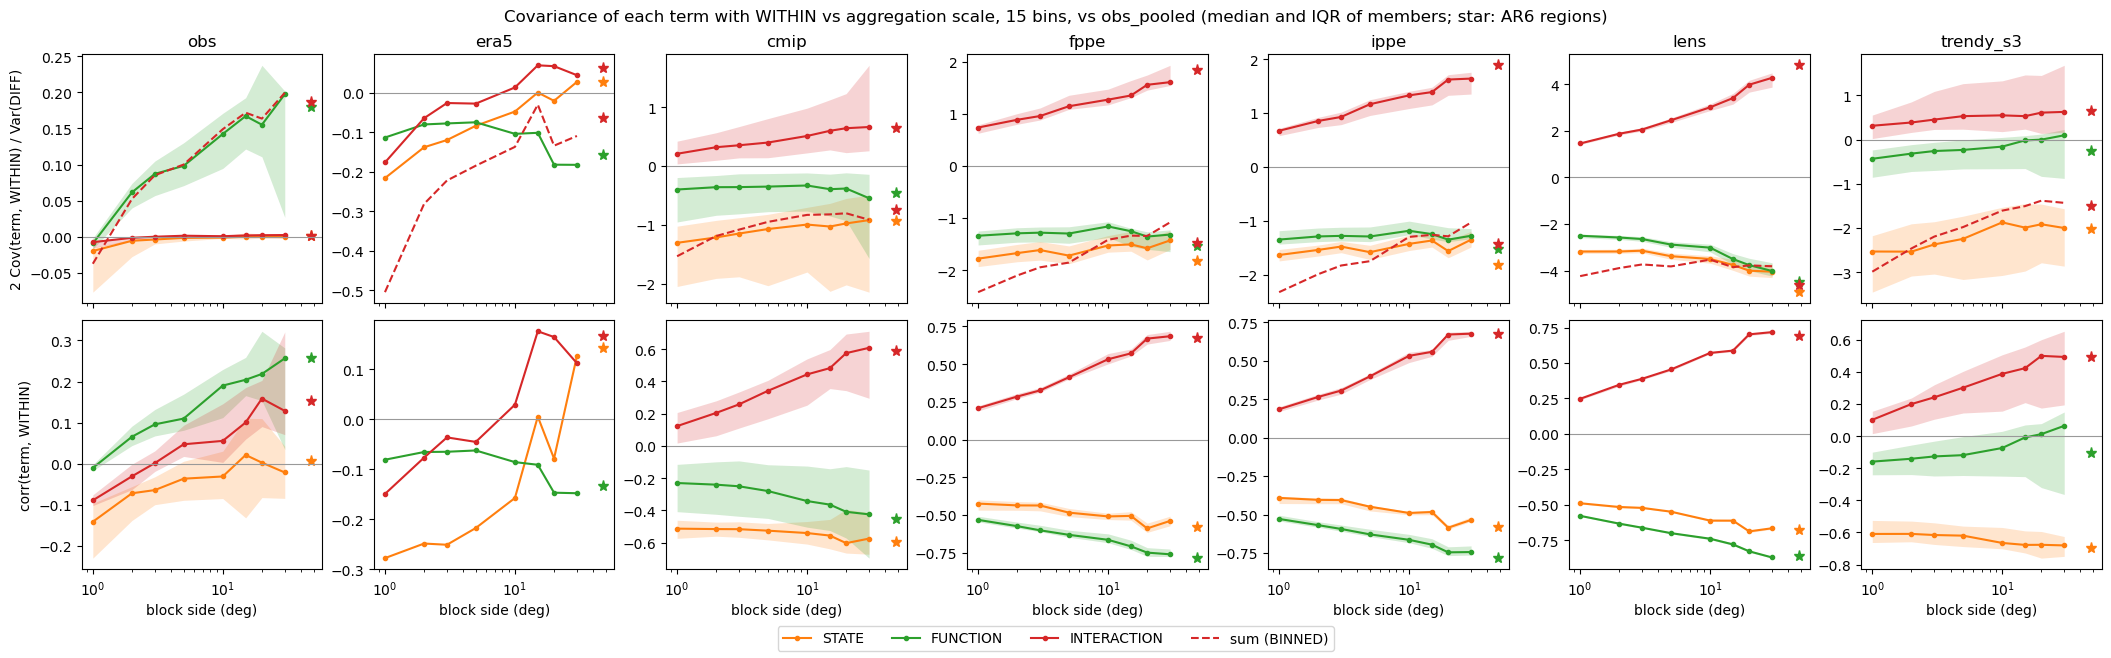

In [ ]:
# 2 Cov(term, WITHIN) / Var(DIFF) (top, dashed: their sum, the BINNED covariance) and corr(term, WITHIN) (bottom)
# vs block side. Lines: median of the members; bands: their IQR; stars (right of the curves): AR6 regions
TERM_COLORS = {"STATE": "C1", "FUNCTION": "C2", "INTERACTION": "C3"}
fig, axes = plt.subplots(2, len(families), figsize=(3 * len(families), 6.5), sharex=True, layout="constrained")
for j, f in enumerate(families):
    med, lo, hi = (family_summary(cov_parts[f], s) for s in ("median", "q25", "q75"))
    reg = family_summary(cov_ar6[f])
    L = med["block_deg"]
    for row, prefix in ((0, "frac_2cov_"), (1, "corr_")):
        ax = axes[row, j]
        for t, c in TERM_COLORS.items():
            ax.plot(L, med[prefix + t], color=c, marker="o", ms=3, label=t)
            ax.fill_between(L, lo[prefix + t], hi[prefix + t], color=c, alpha=0.2, lw=0)
            ax.plot(L.max() * 1.6, float(reg[prefix + t]), marker="*", color=c, ms=8, ls="none")
        if row == 0:
            ax.plot(L, med["frac_2cov"], color="k", ls="--", label="sum (BINNED)")
            ax.plot(L.max() * 1.6, float(reg["frac_2cov"]), marker="*", color="C4", ms=8, ls="none")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_xscale("log")
    axes[0, j].set_title(f)
axes[0, 0].set_ylabel("2 Cov(term, WITHIN) / Var(DIFF)")
axes[1, 0].set_ylabel("corr(term, WITHIN)")
for ax in axes[1]:
    ax.set_xlabel("block side (deg)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
fig.suptitle(f"Covariance of each term with WITHIN vs aggregation scale, {NBINS} bins, vs {REF} "
             "(median and IQR of members; star: AR6 regions)");

## Two-term splits: path A, path B and the symmetric split

BINNED = E_mm − E_rr splits exactly into a state term and a function term, in either order (at each gridcell, with the bin means f of m and r at its bins b_m and b_r):

- **A (function first)**: FUNCTION = f_m(b_r) − f_r(b_r), then STATE + INTERACTION = f_m(b_m) − f_m(b_r), the state shift at m's own bin means;
- **B (state first)**: STATE = f_r(b_m) − f_r(b_r), then FUNCTION + INTERACTION = f_m(b_m) − f_r(b_m), m's function error at m's own bins;
- **symmetric** (Shapley): STATE + INTERACTION/2 and FUNCTION + INTERACTION/2, the mean of A and B, which does not depend on the order.

All three are state = STATE + w·INTERACTION and function = FUNCTION + (1 − w)·INTERACTION, with w = 1 (A), 0 (B) and 0.5 (symmetric). For each split and term T, at each aggregation scale (blocks and AR6 regions, as above; `NBINS` bins, vs `REF`):

- `frac_var_<T>` = Var(T) / Var(DIFF);
- `frac_2cov_<T>` = 2 Cov(T, WITHIN) / Var(DIFF): state + function = `frac_2cov` of the partition above, the same in every split (checked);
- `corr_<T>` = corr(T, WITHIN);
- `frac_2cov_sf` = 2 Cov(state, function) / Var(DIFF), so that frac_var_state + frac_var_function + frac_2cov_sf = frac_BINNED.

The split only moves INTERACTION between the two terms. It cannot change the total covariance with WITHIN, only which term carries it.

Runtime: about 3 minutes (needs `on_support_components`, `block_means`, `region_means`, `family_summary`, `scale_parts` and `ar6_parts` from the cells above).

In [19]:
# Fraction w of INTERACTION given to the state term in each split; the function term gets 1 - w
SPLITS = {"A": 1.0, "B": 0.0, "symmetric": 0.5}


def split_stats(x: xr.Dataset, a: xr.DataArray, dims) -> xr.Dataset:
    """
    For each split of SPLITS, state = STATE + w INTERACTION and function = FUNCTION + (1 - w) INTERACTION,
    across `dims` weighted by `a`: Var(term) / Var(DIFF), 2 Cov(term, WITHIN) / Var(DIFF), corr(term, WITHIN),
    and 2 Cov(state, function) / Var(DIFF) (frac_2cov_sf). Along a new `split` dim.
    """
    def wmean(v):
        return (a * v).sum(dims) / a.sum(dims)

    def wcov(u, v):
        return wmean((u - wmean(u)) * (v - wmean(v)))

    var_diff, var_within = wcov(x["DIFF"], x["DIFF"]), wcov(x["WITHIN"], x["WITHIN"])
    per_split = []
    for w in SPLITS.values():
        terms = {"state": x["STATE"] + w * x["INTERACTION"],
                 "function": x["FUNCTION"] + (1 - w) * x["INTERACTION"]}
        out = xr.Dataset()
        for name, t in terms.items():
            var_t, cov_t = wcov(t, t), wcov(t, x["WITHIN"])
            out[f"frac_var_{name}"] = var_t / var_diff
            out[f"frac_2cov_{name}"] = 2 * cov_t / var_diff
            out[f"corr_{name}"] = cov_t / np.sqrt(var_t * var_within)
        out["frac_2cov_sf"] = 2 * wcov(terms["state"], terms["function"]) / var_diff
        per_split.append(out)
    return xr.concat(per_split, dim="split").assign_coords(split=list(SPLITS))


# Every dataset vs REF, NBINS bins: across blocks of each size (along block_deg) and across the AR6 regions
split_parts, split_ar6 = {}, {}
for f, ds in decomp[NBINS].items():
    x, a = on_support_components(ds.sel(obs_reference=REF).load())
    per_k = [split_stats(*block_means(x, a, k), ("lat", "lon")) for k in BLOCK_CELLS]
    split_parts[f] = xr.concat(per_k, dim="block_deg").assign_coords(block_deg=[k * TARGET_RES for k in BLOCK_CELLS])
    split_ar6[f] = split_stats(*region_means(x, a, ar6), "region")
    # Check: in every split, the state and function covariances with WITHIN add up to frac_2cov of `partition`
    for p, ref in ((split_parts[f], scale_parts[NBINS][f]), (split_ar6[f], ar6_parts[NBINS][f])):
        err = abs(p["frac_2cov_state"] + p["frac_2cov_function"] - ref["frac_2cov"]).max()
        assert float(err) < 1e-3, f"{f}: covariance split does not add up ({float(err):.2g})"
    print(f"{f} done")

obs done
era5 done
cmip done
fppe done
ippe done
lens done
trendy_s3 done


In [20]:
# Table: median over the members of each family, at the gridcell scale, 10 deg blocks and the AR6 regions
COLS = ["frac_var_state", "frac_var_function", "frac_2cov_sf", "frac_2cov_state", "frac_2cov_function",
        "corr_state", "corr_function"]
rows = []
for f in decomp[NBINS]:
    meds = {f"{L:g} deg": family_summary(split_parts[f]).sel(block_deg=L) for L in (TARGET_RES, 10)}
    meds["AR6 regions"] = family_summary(split_ar6[f])
    for scale, med in meds.items():
        for s in SPLITS:
            rows.append({"family": f, "scale": scale, "split": s, **{c: float(med[c].sel(split=s)) for c in COLS}})
with pd.option_context("display.width", 300, "display.max_rows", 100, "display.max_columns", 20,
                       "display.float_format", "{:.3f}".format):
    print(pd.DataFrame(rows).set_index(["family", "scale", "split"]))

                                 frac_var_state  frac_var_function  frac_2cov_sf  frac_2cov_state  frac_2cov_function  corr_state  corr_function
family    scale       split                                                                                                                     
obs       1 deg       A                   0.014              0.426         0.004           -0.026              -0.009      -0.155         -0.010
                      B                   0.011              0.436         0.000           -0.020              -0.018      -0.141         -0.017
                      symmetric           0.012              0.424         0.004           -0.023              -0.015      -0.152         -0.014
          10 deg      A                   0.001              0.432         0.001            0.001               0.142       0.041          0.190
                      B                   0.001              0.428        -0.001           -0.001               0.144      -0.031 

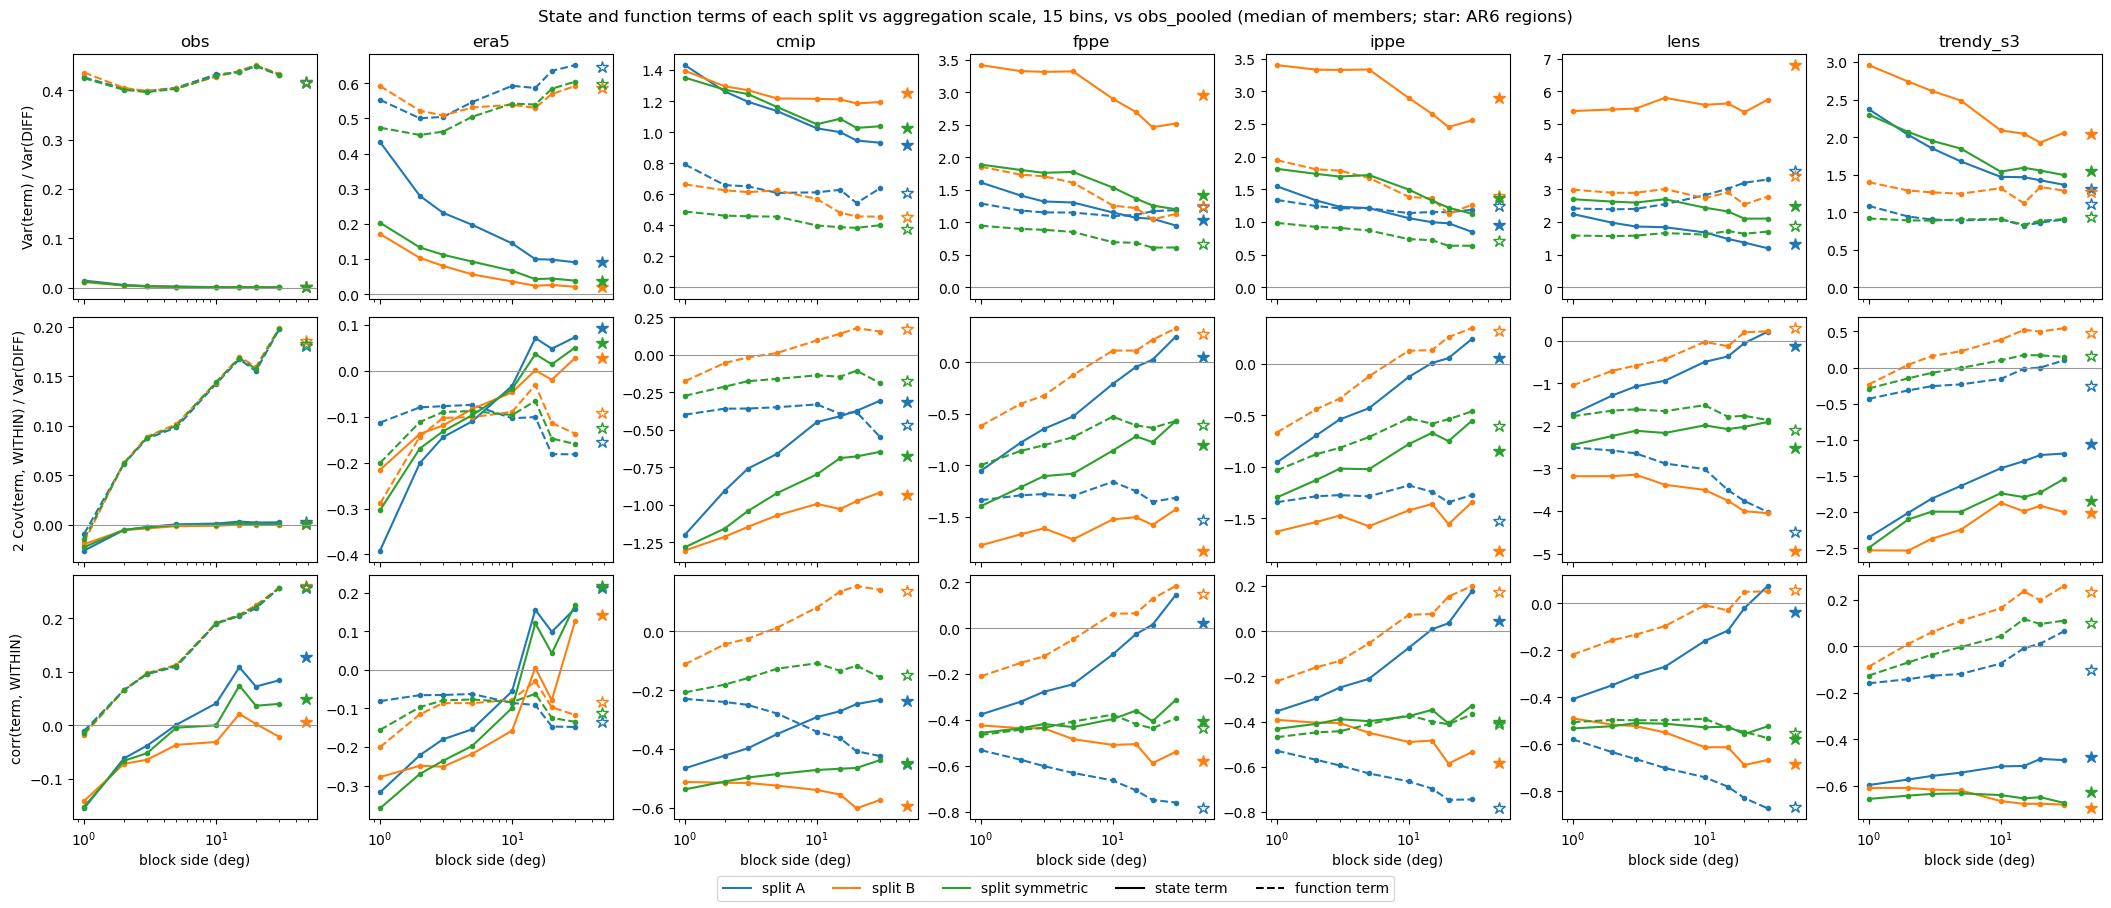

In [21]:
# Var(term) / Var(DIFF) (top), 2 Cov(term, WITHIN) / Var(DIFF) (middle) and corr(term, WITHIN) (bottom) vs block side,
# for each split. Lines: median of the members (solid: state term, dashed: function term);
# stars (right of the curves): AR6 regions (filled: state term, open: function term)
from matplotlib.lines import Line2D

SPLIT_COLORS = {"A": "C0", "B": "C1", "symmetric": "C2"}
TERM_LS = {"state": "-", "function": "--"}
ROWS = {"frac_var_": "Var(term) / Var(DIFF)", "frac_2cov_": "2 Cov(term, WITHIN) / Var(DIFF)",
        "corr_": "corr(term, WITHIN)"}
fig, axes = plt.subplots(len(ROWS), len(families), figsize=(3 * len(families), 9), sharex=True, layout="constrained")
for j, f in enumerate(families):
    med, reg = family_summary(split_parts[f]), family_summary(split_ar6[f])
    L = med["block_deg"]
    for i, prefix in enumerate(ROWS):
        ax = axes[i, j]
        for s, c in SPLIT_COLORS.items():
            for t, ls in TERM_LS.items():
                ax.plot(L, med[prefix + t].sel(split=s), color=c, ls=ls, marker="o", ms=3)
                ax.plot(L.max() * 1.6, float(reg[prefix + t].sel(split=s)), marker="*", ms=9, ls="none",
                        color=c, mfc=c if t == "state" else "none")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_xscale("log")
    axes[0, j].set_title(f)
for ax, label in zip(axes[:, 0], ROWS.values()):
    ax.set_ylabel(label)
for ax in axes[-1]:
    ax.set_xlabel("block side (deg)")
handles = ([Line2D([], [], color=c, label=f"split {s}") for s, c in SPLIT_COLORS.items()]
           + [Line2D([], [], color="k", ls=ls, label=f"{t} term") for t, ls in TERM_LS.items()])
fig.legend(handles=handles, loc="outside lower center", ncol=5)
fig.suptitle(f"State and function terms of each split vs aggregation scale, {NBINS} bins, vs {REF} "
             "(median of members; star: AR6 regions)");

## Regression of INTERACTION on STATE, per member

At each gridcell, STATE = f_r(b_m) − f_r(b_r) is the change of the obs bin means across the bin shift from b_r to b_m, and STATE + INTERACTION = f_m(b_m) − f_m(b_r) is the same change of m's own bin means. The land-area weighted OLS slope of INTERACTION on STATE, Cov(INTERACTION, STATE) / Var(STATE), for every dataset vs `REF` at each aggregation scale (blocks and AR6 regions, as above; `NBINS` bins):

- slope = 0: m's ET changes across the bin shift as much as the obs bin means do;
- slope = −1: m's ET is flat across the bin shift (INTERACTION cancels STATE);
- `ratio` = 1 + slope: the slope of STATE + INTERACTION on STATE, m's change per unit change of the obs bin means.

Against `obs_pooled`, each gridcell's reference bin is a mix of the obs products' bins, so STATE is non-zero almost everywhere (no gridcell sits exactly at STATE = INTERACTION = 0).

`member_slopes` holds every dataset's slope and correlation (one row per dataset, members and pooled).

Runtime: about 3 minutes.

In [22]:
def interaction_regression(x: xr.Dataset, a: xr.DataArray, dims) -> xr.Dataset:
    """
    Land-area weighted OLS of INTERACTION on STATE across `dims`:
    slope = Cov(INTERACTION, STATE) / Var(STATE), corr = corr(INTERACTION, STATE), and ratio = 1 + slope,
    the slope of STATE + INTERACTION = f_m(b_m) - f_m(b_r) on STATE = f_r(b_m) - f_r(b_r).
    """
    def wmean(v):
        return (a * v).sum(dims) / a.sum(dims)

    def wcov(u, v):
        return wmean((u - wmean(u)) * (v - wmean(v)))

    s, i = x["STATE"], x["INTERACTION"]
    var_s, cov_is = wcov(s, s), wcov(i, s)
    slope = cov_is / var_s
    return xr.Dataset({"slope": slope, "corr": cov_is / np.sqrt(var_s * wcov(i, i)), "ratio": 1 + slope})


# Every dataset vs REF, NBINS bins: across blocks of each size (along block_deg) and across the AR6 regions
reg_parts, reg_ar6 = {}, {}
for f, ds in decomp[NBINS].items():
    x, a = on_support_components(ds.sel(obs_reference=REF).load())
    per_k = [interaction_regression(*block_means(x, a, k), ("lat", "lon")) for k in BLOCK_CELLS]
    reg_parts[f] = xr.concat(per_k, dim="block_deg").assign_coords(block_deg=[k * TARGET_RES for k in BLOCK_CELLS])
    reg_ar6[f] = interaction_regression(*region_means(x, a, ar6), "region")
    print(f"{f} done")

# One row per dataset (members and pooled), one column per scale
member_slopes = pd.concat([
    pd.DataFrame({
        "slope 1 deg": reg_parts[f]["slope"].sel(block_deg=TARGET_RES).to_series(),
        "slope 10 deg": reg_parts[f]["slope"].sel(block_deg=10).to_series(),
        "slope AR6": reg_ar6[f]["slope"].to_series(),
        "corr 1 deg": reg_parts[f]["corr"].sel(block_deg=TARGET_RES).to_series(),
        "corr AR6": reg_ar6[f]["corr"].to_series(),
    }).assign(family=f)
    for f in decomp[NBINS]
])

obs done
era5 done
cmip done
fppe done
ippe done
lens done
trendy_s3 done


In [23]:
# Table: median [q25, q75] over the members of each family, and the pooled dataset
COLS = ["slope 1 deg", "slope 10 deg", "slope AR6", "corr 1 deg", "corr AR6"]
members = member_slopes[~member_slopes.index.str.endswith("_pooled")].groupby("family", sort=False)[COLS]
med, q25, q75 = members.median(), members.quantile(0.25), members.quantile(0.75)
table = med.map("{:.2f}".format) + " [" + q25.map("{:.2f}".format) + ", " + q75.map("{:.2f}".format) + "]"
table["n"] = members.size()
pooled = member_slopes[member_slopes.index.str.endswith("_pooled")].set_index("family")[COLS]
with pd.option_context("display.width", 300, "display.max_columns", 20, "display.float_format", "{:.2f}".format):
    print("Members: median [q25, q75]")
    print(table)
    print("\nPooled datasets")
    print(pooled)

Members: median [q25, q75]
                    slope 1 deg          slope 10 deg             slope AR6            corr 1 deg              corr AR6   n
family                                                                                                                     
obs         -0.01 [-0.07, 0.09]    0.04 [-0.07, 0.07]    0.07 [-0.06, 0.16]   -0.01 [-0.12, 0.19]    0.14 [-0.09, 0.31]  12
era5       -0.39 [-0.39, -0.39]     0.20 [0.20, 0.20]     0.02 [0.02, 0.02]  -0.26 [-0.26, -0.26]     0.01 [0.01, 0.01]   1
cmip       -0.38 [-0.66, -0.21]  -0.38 [-0.68, -0.17]  -0.38 [-0.75, -0.14]  -0.48 [-0.69, -0.28]  -0.69 [-0.85, -0.23]  44
fppe       -0.63 [-0.68, -0.60]  -0.64 [-0.69, -0.61]  -0.71 [-0.77, -0.67]  -0.74 [-0.77, -0.71]  -0.80 [-0.84, -0.78]  27
ippe       -0.68 [-0.69, -0.65]  -0.68 [-0.71, -0.65]  -0.75 [-0.78, -0.72]  -0.75 [-0.78, -0.73]  -0.82 [-0.85, -0.81]  27
lens       -0.71 [-0.71, -0.70]  -0.77 [-0.77, -0.76]  -0.86 [-0.87, -0.86]  -0.77 [-0.78, -0.77]  -0.90 

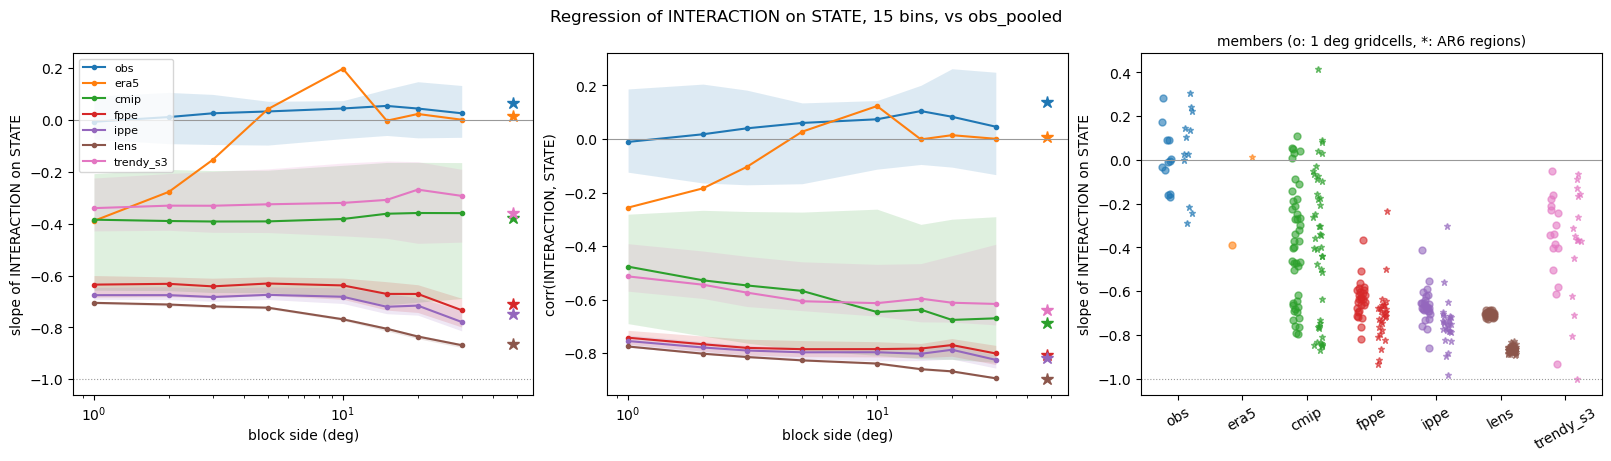

In [24]:
# Left: slope of INTERACTION on STATE vs block side (median and IQR of the members; star: AR6 regions;
# dotted: -1, m's ET flat across the bin shift). Middle: corr(INTERACTION, STATE). Right: every member's slope
# at 1 deg and across the AR6 regions
fam_colors = {f: f"C{k}" for k, f in enumerate(families)}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
for f, c in fam_colors.items():
    med, lo, hi = (family_summary(reg_parts[f], s) for s in ("median", "q25", "q75"))
    reg = family_summary(reg_ar6[f])
    L = med["block_deg"]
    for ax, v in zip(axes[:2], ("slope", "corr")):
        ax.plot(L, med[v], color=c, marker="o", ms=3, label=f)
        ax.fill_between(L, lo[v], hi[v], color=c, alpha=0.15, lw=0)
        ax.plot(L.max() * 1.6, float(reg[v]), marker="*", color=c, ms=9, ls="none")
for ax, label in zip(axes[:2], ("slope of INTERACTION on STATE", "corr(INTERACTION, STATE)")):
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("block side (deg)")
    ax.set_ylabel(label)
axes[0].axhline(-1, color="0.6", lw=0.8, ls=":")
axes[0].legend(fontsize=8)

ax = axes[2]
rng = np.random.default_rng(0)  # horizontal jitter of the member points
for j, (f, c) in enumerate(fam_colors.items()):
    m = member_slopes[(member_slopes["family"] == f) & ~member_slopes.index.str.endswith("_pooled")]
    for dx, col, mk in ((-0.17, "slope 1 deg", "o"), (0.17, "slope AR6", "*")):
        ax.plot(j + dx + rng.uniform(-0.07, 0.07, len(m)), m[col], marker=mk, ls="none", color=c, ms=5, alpha=0.6)
ax.axhline(0, color="0.6", lw=0.8)
ax.axhline(-1, color="0.6", lw=0.8, ls=":")
ax.set_xticks(range(len(families)), families, rotation=30)
ax.set_ylabel("slope of INTERACTION on STATE")
ax.set_title("members (o: 1 deg gridcells, *: AR6 regions)", fontsize=10)
fig.suptitle(f"Regression of INTERACTION on STATE, {NBINS} bins, vs {REF}");